In [ ]:
import pandas as pd

daily_df = pd.read_csv('data/daily_cleaned.csv', index_col=0, parse_dates=True)
print(df.head())

            PM2.5 (ug/m3)  PM10 (ug/m3)  NO (ug/m3)  NO2 (ug/m3)  NOx (ppb)  \
From Date                                                                     
2016-07-01      12.095714     49.892857   14.945000    39.115000  30.233571   
2016-07-02      19.537857     61.216905   21.658905    43.253905  37.183333   
2016-07-03      14.162500     46.146250   12.116250    41.458750  29.240833   
2016-07-04       9.677083     22.793542    7.494792    39.542708  24.841667   
2016-07-05       4.718750     17.228750   15.559167    39.981667  31.032917   

            NH3 (ug/m3)  SO2 (ug/m3)  CO (mg/m3)  Ozone (ug/m3)  \
From Date                                                         
2016-07-01     7.620000     6.340714    0.425000      13.821429   
2016-07-02     7.522000     5.283000    0.872190      12.664048   
2016-07-03     8.693750     5.548958    0.763333      13.643750   
2016-07-04     7.065625     5.897500    0.621875      14.103750   
2016-07-05     7.411875     5.073750    0.75

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Resample daily PM2.5 into Monthly averages (81 months: Jul 2016 – Mar 2023)
monthly_pm25 = daily_df['PM2.5 (ug/m3)'].resample('ME').mean().interpolate()

print("Total months:", len(monthly_pm25))
print("Date range  :", monthly_pm25.index.min().strftime('%Y-%m'), "to", monthly_pm25.index.max().strftime('%Y-%m'))
monthly_pm25.head()

Total months: 81
Date range  : 2016-07 to 2023-03


From Date
2016-07-31    13.896850
2016-08-31    12.019347
2016-09-30    15.636766
2016-10-31    41.574077
2016-11-30    56.648629
Freq: ME, Name: PM2.5 (ug/m3), dtype: float64

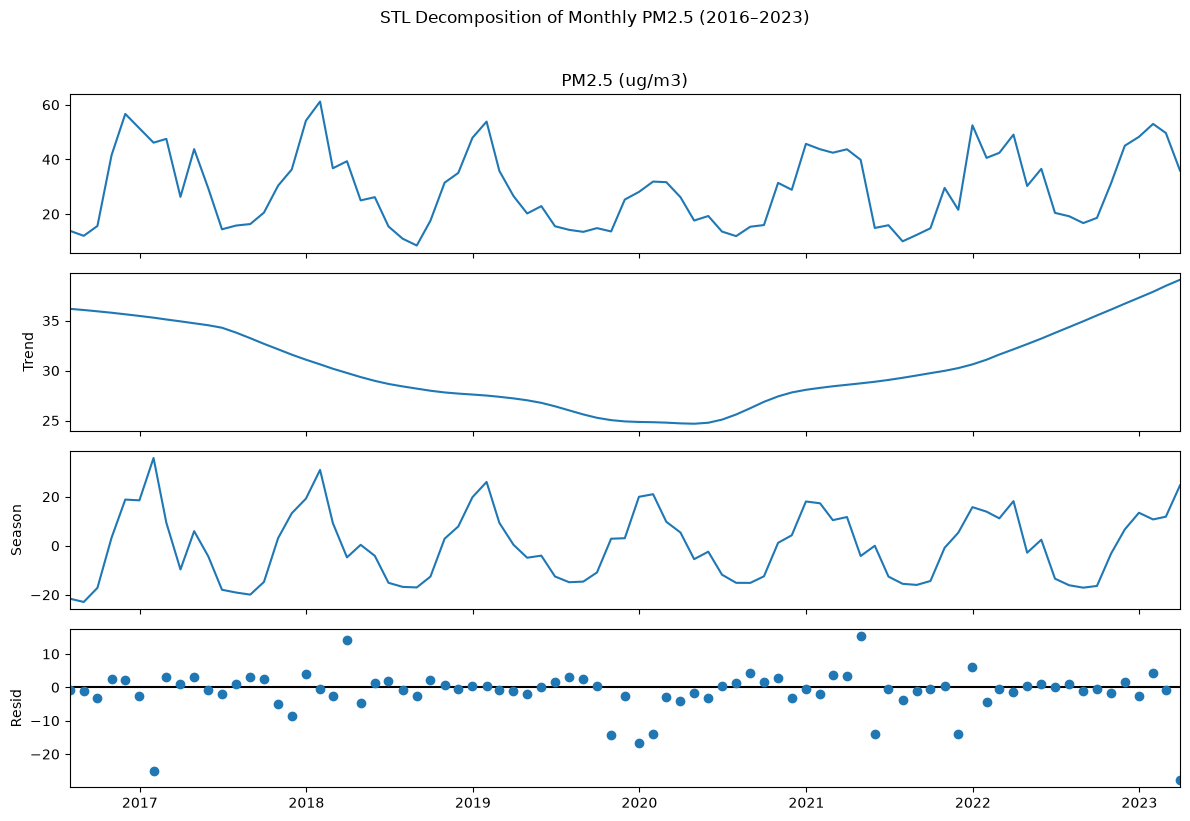

In [7]:
from statsmodels.tsa.seasonal import STL

stl = STL(monthly_pm25, period=12, robust=True)
result = stl.fit()

fig = result.plot()
fig.set_size_inches(12, 8)
plt.suptitle('STL Decomposition of Monthly PM2.5 (2016–2023)', y=1.02)
plt.tight_layout()
plt.show()

In [10]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error

# 1. Split chronologically: Train (2016–2021) vs. Test (2022–2023)
train = monthly_pm25[:'2021-12-31']
test = monthly_pm25['2022-01-01':]

# 2. Fit Holt-Winters model with additive trend and 12-month seasonality
model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit()

# 3. Forecast the next 15 months (the exact length of the test set)
forecast = model.forecast(len(test))

# 4. Evaluate accuracy using MAE and RMSE
mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(np.mean((test - forecast) ** 2))

print(f"MAE  (Average Error): {mae:.2f} µg/m³")
print(f"RMSE (Penalty Error): {rmse:.2f} µg/m³")

MAE  (Average Error): 8.12 µg/m³
RMSE (Penalty Error): 9.34 µg/m³


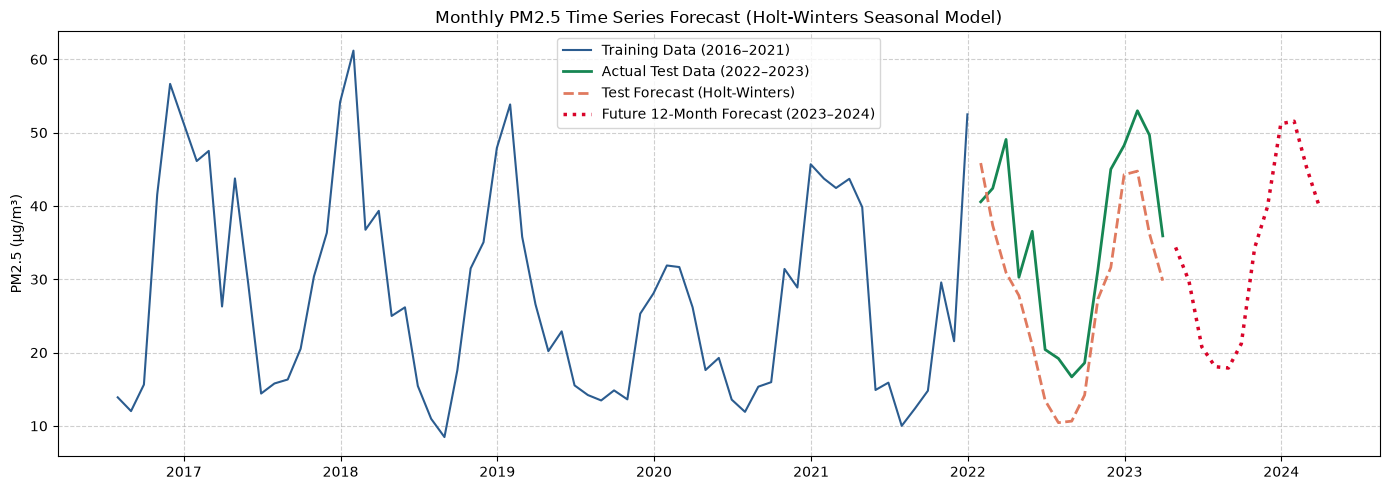

In [11]:
# Refit on 100% of available data to project 12 months into the future
full_model = ExponentialSmoothing(
    monthly_pm25,
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit()
future_12m = full_model.forecast(12)

plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label='Training Data (2016–2021)', color='#2b5c8f')
plt.plot(test.index, test, label='Actual Test Data (2022–2023)', color='#168653', linewidth=2)
plt.plot(forecast.index, forecast, label='Test Forecast (Holt-Winters)', color='#e07a5f', linestyle='--', linewidth=2)
plt.plot(future_12m.index, future_12m, label='Future 12-Month Forecast (2023–2024)', color='#d90429', linestyle=':', linewidth=2.5)

plt.title('Monthly PM2.5 Time Series Forecast (Holt-Winters Seasonal Model)')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()